# Task 4 (Medium) – Trend Prediction Analysis
**Internship:** Auspify Technologies – Data Science Program  
**Intern:** Shabbir Moomin (Colombo, Sri Lanka)  
**Dataset:** `Netflix_Cleaned.csv` (Task 1 output – same records as the provided `Dataset_1.csv`)

**Goal:** analyse historical content trends (by **release year**) and forecast future content growth.

**Workflow**
1. Prepare release-year data
2. Analyze yearly content trends
3. Build forecasting models
4. Visualize future predictions
5. Interpret results

**Heads-up:** this is a *very short* time series (one value per year, ~20 usable points), so forecasts are rough and should come with honest uncertainty. The notebook is deliberately explicit about that.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA

warnings.filterwarnings('ignore')     # statsmodels is chatty with convergence warnings on tiny series
sns.set_theme(style='whitegrid')
RED, GREY, BLUE = '#E50914', '#564d4d', '#1f77b4'
plt.rcParams['figure.figsize'] = (10, 5)

df = pd.read_csv('Netflix_Cleaned.csv', parse_dates=['date_added'])
print(df.shape)

(8786, 34)


## Step 1 – Prepare release-year data

In [2]:
# count titles per release year, total and by type; fill missing years with 0 so the series has no gaps
years = pd.RangeIndex(df['release_year'].min(), df['release_year'].max() + 1, name='release_year')
by_type = (df.groupby(['release_year', 'type']).size().unstack(fill_value=0)
             .reindex(years, fill_value=0))
by_type['Total'] = by_type.sum(axis=1)
print('Years covered:', years.min(), '-', years.max())
by_type.tail(12)

Years covered: 1925 - 2021


type,Movie,TV Show,Total
release_year,,,
2010,153,39,192
2011,145,40,185
2012,173,63,236
2013,225,61,286
2014,263,88,351
2015,396,159,555
2016,658,243,901
2017,765,265,1030
2018,766,378,1144


In [3]:
# how sparse is the old data?
print('Titles released before 2000:', (df['release_year'] < 2000).sum(), f"({(df['release_year'] < 2000).mean():.1%})")
print('Years with fewer than 20 titles:', (by_type['Total'] < 20).sum(), 'out of', len(by_type))

# is the latest release year complete? compare with the last date a title was added
print('Last date_added in data:', df['date_added'].max().date())
print('Titles with release_year 2021:', (df['release_year'] == 2021).sum())

Titles released before 2000: 525 (6.0%)
Years with fewer than 20 titles: 66 out of 97
Last date_added in data: 2021-09-25
Titles with release_year 2021: 592


### Data-preparation decisions
- **Modelling window = 2000–2020.** Before 2000 the counts are tiny and scattered (old classics/legacy titles), which would distort a trend model.
- **2021 is excluded from training.** The dataset ends on 25 Sep 2021, so 2021 is only a *partial* year (≈ 3 quarters at best) – treating it as a real drop would teach the model a false decline. I keep it as a "partial actual" to sanity-check the 2021 forecast.
- **Survivorship caveat:** the file is a snapshot of what was on Netflix in 2021, so older release years only include titles that *stayed* in the catalogue. Counts per release year are "titles available", not "titles produced".

In [4]:
# training series
ts = by_type.loc[2000:2020].copy()
partial_2021 = by_type.loc[2021]
print(ts.shape)
partial_2021

(21, 3)


type
Movie      277
TV Show    315
Total      592
Name: 2021, dtype: int64

## Step 2 – Analyze yearly content trends

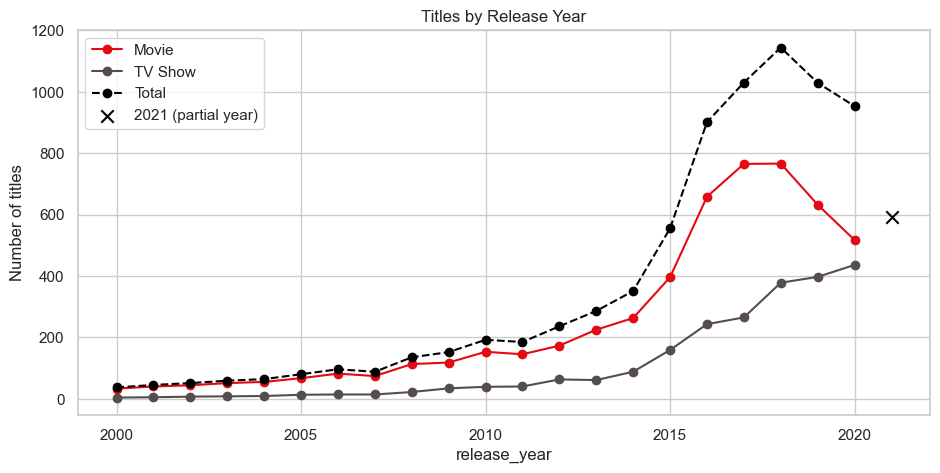

In [5]:
fig, ax = plt.subplots(figsize=(11, 5))
ts[['Movie', 'TV Show']].plot(ax=ax, marker='o', color=[RED, GREY])
ts['Total'].plot(ax=ax, marker='o', color='black', ls='--', label='Total')
ax.scatter([2021], [partial_2021['Total']], color='black', marker='x', s=80, zorder=5, label='2021 (partial year)')
ax.set_title('Titles by Release Year'); ax.set_ylabel('Number of titles'); ax.legend()
plt.show()

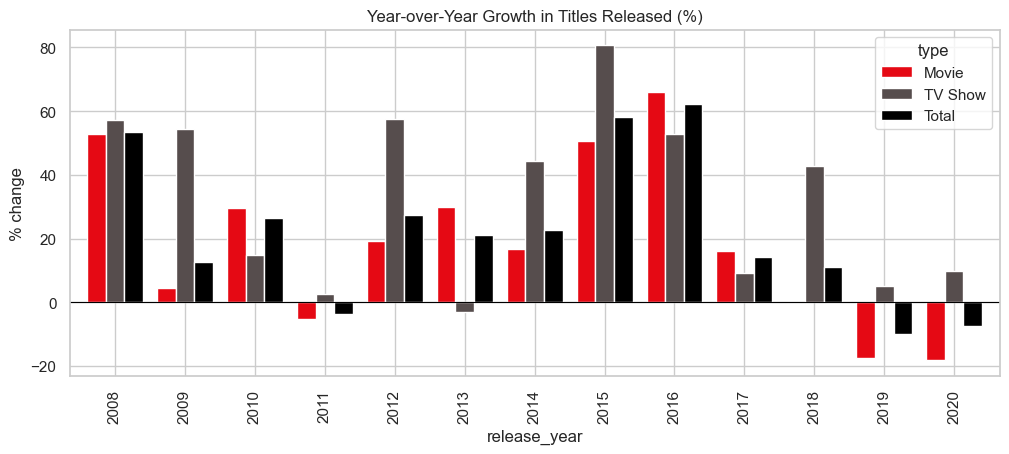

In [6]:
# year-over-year growth (%)
yoy = ts[['Movie', 'TV Show', 'Total']].pct_change() * 100
ax = yoy.loc[2008:].plot(kind='bar', figsize=(12, 4.5), color=[RED, GREY, 'black'], width=0.8)
ax.axhline(0, color='black', lw=.8)
ax.set_title('Year-over-Year Growth in Titles Released (%)'); ax.set_ylabel('% change')
plt.show()

In [7]:
# decade-style summary + CAGR + peaks
def cagr(s, start, end):
    return (s[end] / s[start]) ** (1 / (end - start)) - 1

summary_tbl = pd.DataFrame({
    'peak_year':  ts[['Movie', 'TV Show', 'Total']].idxmax(),
    'peak_count': ts[['Movie', 'TV Show', 'Total']].max(),
    'CAGR_2010_2018': [cagr(ts[c], 2010, 2018) for c in ['Movie', 'TV Show', 'Total']],
    'change_2018_2020_%': [(ts[c][2020] / ts[c][2018] - 1) * 100 for c in ['Movie', 'TV Show', 'Total']],
}).round(3)
summary_tbl

,peak_year,peak_count,CAGR_2010_2018,change_2018_2020_%
type,,,,
Movie,2018,766,0.223,-32.507
TV Show,2020,436,0.328,15.344
Total,2018,1144,0.250,-16.696


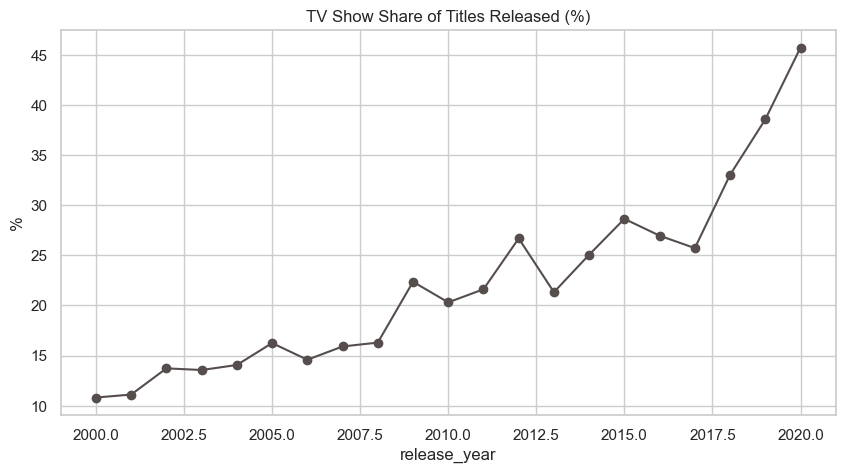

{2005: 16.2, 2010: 20.3, 2015: 28.6, 2018: 33.0, 2020: 45.8}


In [8]:
# TV share of releases over time - is the catalogue shifting from movies to series?
share = (ts['TV Show'] / ts['Total'] * 100)
ax = share.plot(marker='o', color=GREY)
ax.set_title('TV Show Share of Titles Released (%)'); ax.set_ylabel('%')
plt.show()
print(share.loc[[2005, 2010, 2015, 2018, 2020]].round(1).to_dict())

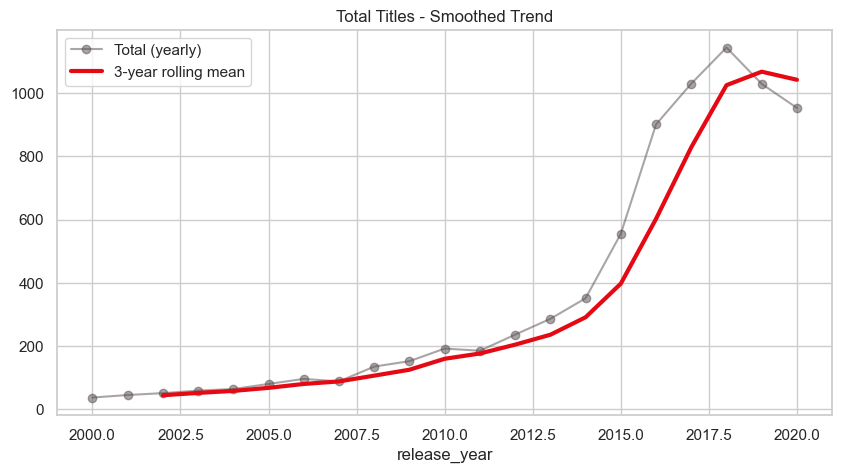

In [9]:
# 3-year rolling mean smooths out the noise and shows the underlying direction
ax = ts['Total'].plot(marker='o', alpha=.5, label='Total (yearly)', color=GREY)
ts['Total'].rolling(3).mean().plot(ax=ax, lw=3, color=RED, label='3-year rolling mean')
ax.set_title('Total Titles - Smoothed Trend'); ax.legend(); plt.show()

## Step 3 – Build forecasting models
Candidate models (kept simple on purpose – there are only 21 data points):

| Model | Idea |
|---|---|
| **Naive** | next year = last year (baseline every model must beat) |
| **Linear** | straight-line trend |
| **Polynomial (deg 2)** | curved trend – can capture a peak |
| **Log-linear (exponential)** | constant % growth |
| **Holt (damped trend)** | exponential smoothing with a trend that fades out over time |
| **ARIMA(1,1,1)** | autoregressive model on year-to-year changes |

**Evaluation (time-based - no shuffling!):**
1. **Rolling-origin 1-step-ahead:** repeatedly train up to year *t*, predict *t+1* (2013 → 2020, 8 predictions). This is the main selection criterion.
2. **Multi-year hold-out:** train 2000–2016, forecast 2017–2020 in one go - shows how models behave over a longer horizon.

Metrics: MAE, RMSE, MAPE (lower = better).

In [10]:
# each model is a function: (train values, horizon h) -> array of h forecasts
def f_naive(y, h):  return np.repeat(y[-1], h)

def f_linear(y, h):
    t = np.arange(len(y)); c = np.polyfit(t, y, 1)
    return np.polyval(c, np.arange(len(y), len(y) + h))

def f_poly2(y, h):
    t = np.arange(len(y)); c = np.polyfit(t, y, 2)
    return np.clip(np.polyval(c, np.arange(len(y), len(y) + h)), 0, None)   # counts can't be negative

def f_loglin(y, h):
    t = np.arange(len(y)); c = np.polyfit(t, np.log1p(y), 1)
    return np.expm1(np.polyval(c, np.arange(len(y), len(y) + h)))

def f_holt(y, h):
    m = ExponentialSmoothing(y.astype(float), trend='add', damped_trend=True,
                             initialization_method='estimated').fit()
    return m.forecast(h)

def f_arima(y, h):
    return ARIMA(y.astype(float), order=(1, 1, 1)).fit().forecast(h)

MODELS = {'Naive': f_naive, 'Linear': f_linear, 'Poly (deg 2)': f_poly2,
          'Log-linear': f_loglin, 'Holt (damped)': f_holt, 'ARIMA(1,1,1)': f_arima}

def metrics(actual, pred):
    actual, pred = np.asarray(actual, float), np.asarray(pred, float)
    err = actual - pred
    return dict(MAE=np.mean(np.abs(err)), RMSE=np.sqrt(np.mean(err ** 2)),
                MAPE=np.mean(np.abs(err / actual)) * 100)

In [11]:
def rolling_eval(series, first_test=2013):
    # expanding-window, 1-step-ahead
    y_all, idx = series.values, series.index
    rows = {n: [] for n in MODELS}
    test_years = [yr for yr in idx if yr >= first_test]
    for yr in test_years:
        train = series.loc[:yr - 1].values
        for n, f in MODELS.items():
            rows[n].append(float(f(train, 1)[0]))
    actual = series.loc[test_years].values
    return pd.DataFrame({n: metrics(actual, p) for n, p in rows.items()}).T, pd.DataFrame(rows, index=test_years), actual

def holdout_eval(series, split=2016):
    train, test = series.loc[:split], series.loc[split + 1:]
    preds = {n: f(train.values, len(test)) for n, f in MODELS.items()}
    return pd.DataFrame({n: metrics(test.values, p) for n, p in preds.items()}).T, pd.DataFrame(preds, index=test.index)

roll_tbl, roll_preds, roll_actual = rolling_eval(ts['Total'])
hold_tbl, hold_preds = holdout_eval(ts['Total'])
print('ROLLING-ORIGIN 1-step-ahead (Total titles):'); display(roll_tbl.round(1).sort_values('RMSE'))
print('MULTI-YEAR HOLD-OUT (train 2000-2016, test 2017-2020):'); display(hold_tbl.round(1).sort_values('RMSE'))

ROLLING-ORIGIN 1-step-ahead (Total titles):


,MAE,RMSE,MAPE
Holt (damped),116.1,142.5,15.2
"ARIMA(1,1,1)",118.7,144.8,15.3
Naive,137.4,164.6,19.1
Poly (deg 2),193.3,231.8,23.2
Log-linear,214.3,261.4,24.6
Linear,268.8,328.0,33.5


MULTI-YEAR HOLD-OUT (train 2000-2016, test 2017-2020):


,MAE,RMSE,MAPE
Naive,138.0,153.9,12.9
Poly (deg 2),183.6,203.5,17.8
Log-linear,242.6,270.0,23.1
Linear,454.7,464.9,43.4
"ARIMA(1,1,1)",697.8,800.1,69.1
Holt (damped),718.4,833.9,71.3


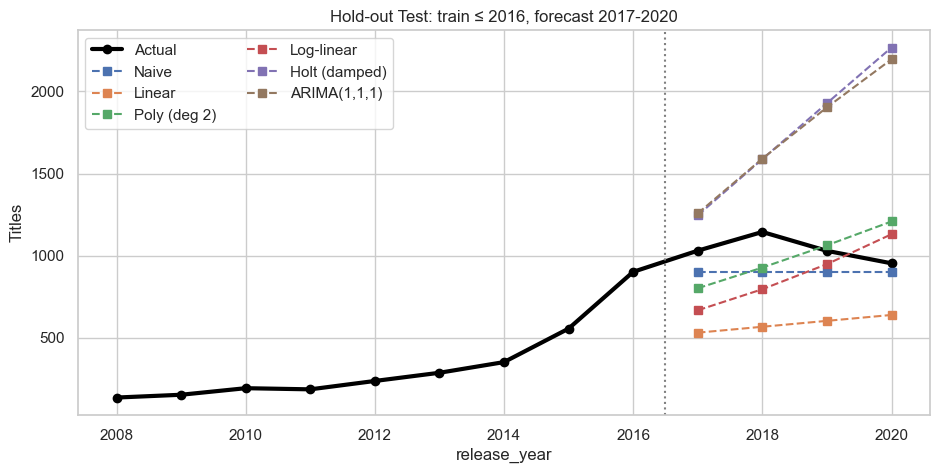

In [12]:
# visual check of the multi-year hold-out: who tracks reality?
fig, ax = plt.subplots(figsize=(11, 5))
ts['Total'].loc[2008:].plot(ax=ax, color='black', lw=3, marker='o', label='Actual')
for n in MODELS:
    ax.plot(hold_preds.index, hold_preds[n], marker='s', ls='--', label=n)
ax.axvline(2016.5, color='grey', ls=':')
ax.set_title('Hold-out Test: train ≤ 2016, forecast 2017-2020'); ax.set_ylabel('Titles'); ax.legend(ncol=2)
plt.show()

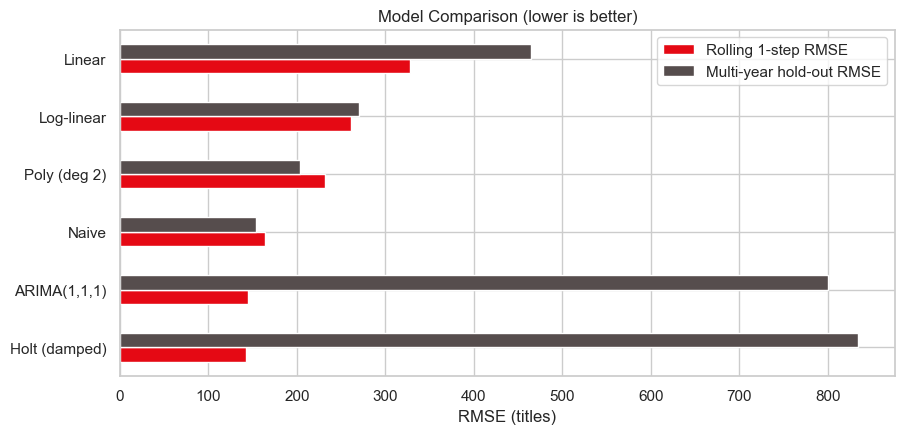

In [13]:
# model comparison chart (RMSE, both evaluation schemes)
cmp = pd.DataFrame({'Rolling 1-step RMSE': roll_tbl['RMSE'], 'Multi-year hold-out RMSE': hold_tbl['RMSE']})
ax = cmp.sort_values('Rolling 1-step RMSE').plot(kind='barh', color=[RED, GREY], figsize=(10, 4.5))
ax.set_title('Model Comparison (lower is better)'); ax.set_xlabel('RMSE (titles)'); plt.show()

In [14]:
# pick the winner per series by rolling-origin RMSE; do the same for Movies and TV Shows separately
def pick_best(series):
    tbl, _, _ = rolling_eval(series)
    return tbl['RMSE'].idxmin(), tbl

best = {}
for col in ['Total', 'Movie', 'TV Show']:
    name, tbl = pick_best(ts[col])
    best[col] = (name, tbl.loc[name, 'RMSE'])
    print(f"{col:8s} -> best model: {name:14s} (rolling RMSE = {tbl.loc[name, 'RMSE']:.1f})")

Total    -> best model: Holt (damped)  (rolling RMSE = 142.5)
Movie    -> best model: ARIMA(1,1,1)   (rolling RMSE = 111.7)
TV Show  -> best model: Holt (damped)  (rolling RMSE = 51.1)


## Step 4 – Visualize future predictions

In [15]:
# refit on all 2000-2020 data and forecast 2021-2026
H = 6
future_years = np.arange(2021, 2021 + H)
fc = {}
for col in ['Total', 'Movie', 'TV Show']:
    name, rmse = best[col]
    pred = np.clip(MODELS[name](ts[col].values, H), 0, None)
    # rough ~80% interval: +/-1.28 x rolling RMSE, widening with sqrt(horizon). a rule of thumb, not exact stats
    width = 1.28 * rmse * np.sqrt(np.arange(1, H + 1))
    fc[col] = pd.DataFrame({'forecast': pred, 'low': np.clip(pred - width, 0, None), 'high': pred + width},
                           index=future_years).round(0)
fc['Total']

,forecast,low,high
2021,868.0,686.0,1050.0
2022,784.0,526.0,1042.0
2023,702.0,386.0,1018.0
2024,620.0,255.0,985.0
2025,539.0,131.0,947.0
2026,459.0,12.0,906.0


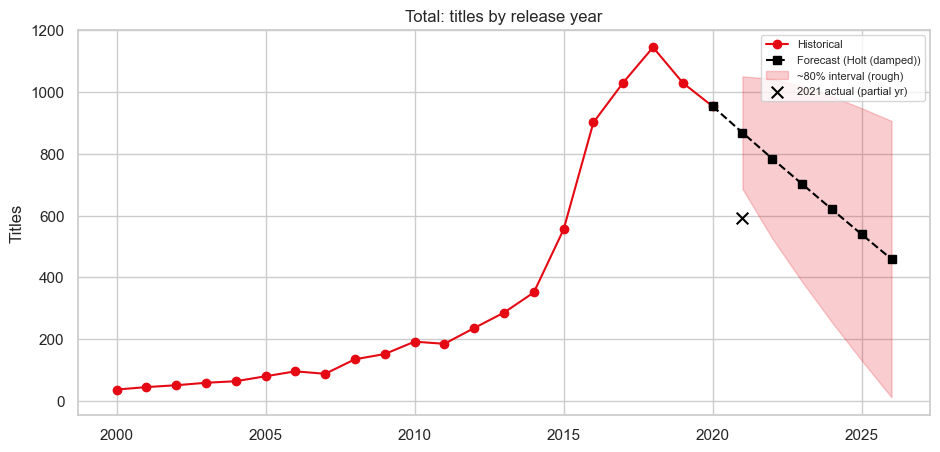

In [16]:
def plot_fc(col, color, ax):
    hist = ts[col]
    ax.plot(hist.index, hist.values, marker='o', color=color, label='Historical')
    f = fc[col]
    ax.plot(np.r_[2020, f.index], np.r_[hist.iloc[-1], f['forecast']], marker='s', ls='--', color='black', label=f'Forecast ({best[col][0]})')
    ax.fill_between(f.index, f['low'], f['high'], color=color, alpha=.2, label='~80% interval (rough)')
    ax.scatter([2021], [partial_2021[col]], marker='x', color='black', s=70, zorder=5, label='2021 actual (partial yr)')
    ax.set_title(f'{col}: titles by release year'); ax.set_ylabel('Titles'); ax.legend(fontsize=8)

fig, ax = plt.subplots(figsize=(11, 5))
plot_fc('Total', RED, ax); plt.show()

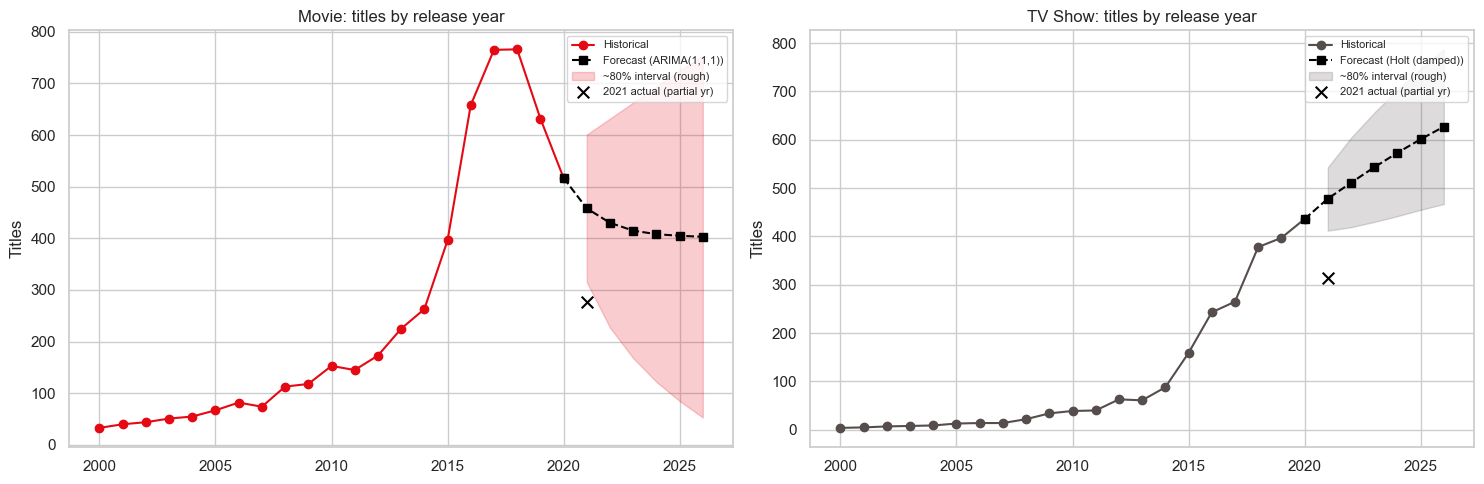

,Movie,TV Show
2021,458.0,478.0
2022,430.0,511.0
2023,415.0,543.0
2024,408.0,573.0
2025,405.0,601.0
2026,403.0,627.0


In [17]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
plot_fc('Movie', RED, ax[0]); plot_fc('TV Show', GREY, ax[1])
plt.tight_layout(); plt.show()
pd.concat({'Movie': fc['Movie']['forecast'], 'TV Show': fc['TV Show']['forecast']}, axis=1)

In [18]:
# consistency check: does the sum of the Movie + TV forecasts agree with the direct Total forecast?
chk = pd.DataFrame({'Total (direct)': fc['Total']['forecast'],
                    'Movie + TV (bottom-up)': fc['Movie']['forecast'] + fc['TV Show']['forecast']})
chk['gap'] = chk.iloc[:, 1] - chk.iloc[:, 0]
chk

,Total (direct),Movie + TV (bottom-up),gap
2021,868.0,936.0,68.0
2022,784.0,941.0,157.0
2023,702.0,958.0,256.0
2024,620.0,981.0,361.0
2025,539.0,1006.0,467.0
2026,459.0,1030.0,571.0


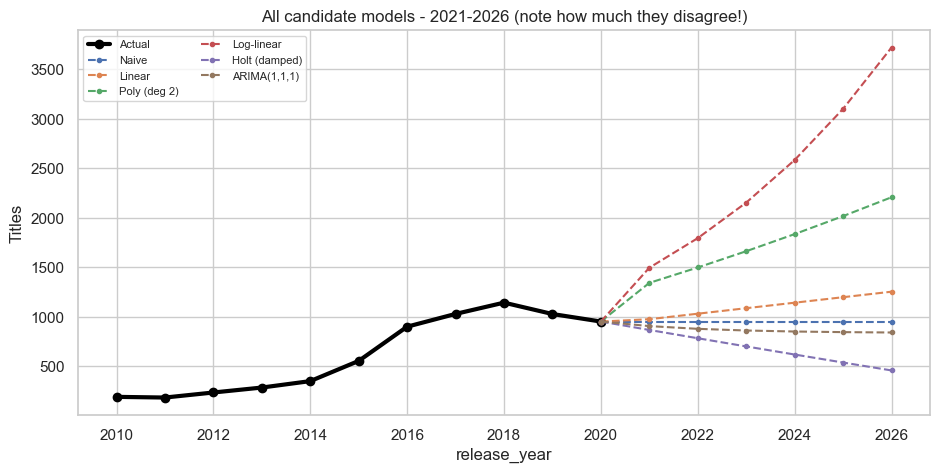

In [19]:
# scenario view: a single forecast hides the real uncertainty, so show what each model *would* say
fig, ax = plt.subplots(figsize=(11, 5))
ts['Total'].loc[2010:].plot(ax=ax, color='black', lw=3, marker='o', label='Actual')
for n, f in MODELS.items():
    ax.plot(np.r_[2020, future_years], np.r_[ts['Total'].iloc[-1], np.clip(f(ts['Total'].values, H), 0, 8000)], ls='--', marker='.', label=n)
ax.set_title('All candidate models - 2021-2026 (note how much they disagree!)'); ax.set_ylabel('Titles'); ax.legend(ncol=2, fontsize=8)
plt.show()

## Step 5 – Interpret results

## Summary of results

**What the history shows (titles by release year, 2000–2020)**
- Output grew very fast through the 2010s: total titles rose at ~25% a year between 2010 and 2018 (Movies ~22%, TV Shows ~33%), peaking in **2018 (1,144 titles)**.
- Since then the two types have diverged: **Movies peaked in 2018 (766) and fell ~33% by 2020 (517)**, while **TV Shows kept growing to a 2020 peak of 436 (+15% vs 2018)**.
- TV's share of titles climbed from ~16% (2005) and ~29% (2015) to **~46% in 2020** - the catalogue is shifting from movies to series.
- 2021 is only a partial year (data ends 25 Sep 2021) and is excluded from training; it already holds 592 titles (277 movies, 315 TV shows).

**Model comparison**

| Evaluation | Best model | Result |
|---|---|---|
| Rolling 1-step-ahead (2013–2020), Total | **Holt (damped)** | RMSE ≈ 142, MAPE ≈ 15% (naive: RMSE ≈ 165) |
| Multi-year hold-out (train ≤ 2016, test 2017–2020) | Naive | RMSE ≈ 154; ARIMA / Holt overshoot badly (RMSE > 800) |

- For **one-year-ahead** forecasts, damped Holt and ARIMA beat the naive baseline, but only by roughly 13–14% - modest skill.
- For **multi-year** forecasts, every trend-following model failed on the 2017–2020 test because they extrapolated the 2010–2016 boom while real output peaked in 2018 and then fell. Straight-line and exponential models are the worst (they keep growing). This is a real warning: *the history up to 2016 gave no signal of the coming slowdown.*

**Forecast 2021–2026 (selected model per series)**

| Series | Model | 2021 | 2026 |
|---|---|---|---|
| Total | Holt (damped) | ~890 | ~710 (rough 80% range 270–1,160) |
| Movies | ARIMA(1,1,1) | ~460 | ~400 |
| TV Shows | Holt (damped) | ~480 | ~630 |

- **Movies:** flat-to-declining at roughly 400–460 titles per release year.
- **TV Shows:** continued steady growth, from ~480 to ~630.
- Summing the Movie and TV forecasts gives ~1,030 titles for 2026 vs ~710 from the direct Total model - the two approaches disagree by ~300 titles, so a fair reading is "**roughly 700–1,000 titles per release year by 2026**, with the mix tilting further towards TV".

**How much to trust this**
- Only 21 yearly data points → wide uncertainty; the shaded bands are a rule-of-thumb (±1.28 × RMSE, widening with horizon), not exact statistical intervals.
- The dataset is a **2021 snapshot**: recent release years may be incomplete, older titles that left the platform are missing (survivorship bias), and 2020 is distorted by COVID-19 production shutdowns. Part of the "decline" in Movies may therefore be data-related rather than real.
- The forecast describes *titles in this catalogue by release year*, not Netflix's real production budget or global output.

**Possible improvements:** use `date_added` (when Netflix actually added content) as a second series; add external data (production spend, subscribers); try Prophet / SARIMAX with regressors; model Movies and TV jointly; and re-run when a fuller, more recent snapshot is available.
